# Exercise 2: Items as text

Inspired by [Wulff and Mata (2025)](https://doi.org/10.1038/s41562-024-02089-y). We build the full pipeline from the abstract: start from the raw text of 300 personality items, extract embeddings, compute pairwise similarities, compare them with the observed correlations between participants' responses, map the items in two dimensions, and try to recover the test's construct structure from the item text alone.

By the end you will have seen:
- how to extract features from items with a pre-trained model
- how well semantic similarity predicts the empirical correlation between items, and what it misses
- what a map of the item space shows, and what it does not
- where recovering constructs from text works, where it fails, and what a model fine-tuned on items changes

## Environment setup

Run the cell below.

In [1]:
import sys
if 'google.colab' in sys.modules:  # install packages when running on Google Colab
    !pip install sentence-transformers pacmap &> /dev/null

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# Data is read straight from the public course repository: nothing to upload or mount.
DATA = "https://raw.githubusercontent.com/dwulff/LLM4BeSci_2025MetaRep/main/day_2/"

## 1. The items

The cell below loads the items into a `pandas.DataFrame` with three columns: `factor` (the Big Five factor), `construct` (the facet) and `item` (the text). There are 300 items, 10 per facet, 6 facets per factor.

Run the cell below.

In [2]:
personality = pd.read_csv(DATA + 'items.csv')
personality

,factor,construct,item
0,Conscientiousness,Achievement-Striving,Go straight for the goal.
1,Conscientiousness,Achievement-Striving,Plunge into tasks with all my heart.
2,Conscientiousness,Achievement-Striving,Demand quality.
3,Conscientiousness,Achievement-Striving,Set high standards for myself and others.
4,Conscientiousness,Achievement-Striving,Turn plans into actions.
...,...,...,...
295,Neuroticism,Vulnerability,Remain calm under pressure.
296,Neuroticism,Vulnerability,Am calm even in tense situations.
297,Neuroticism,Vulnerability,Can handle complex problems.
298,Neuroticism,Vulnerability,Readily overcome setbacks.


## 2. Extracting features from the items

The cell below loads the embedding model and extracts a vector for each item. The result is a table with 300 rows (items) and 384 columns (features).

Run the cell below.

In [3]:
# Load the pre-trained model. Exercise 1 used the same one.
model = SentenceTransformer('all-MiniLM-L6-v2')

# Extract features and keep them in a DataFrame indexed by item text
item_features = pd.DataFrame(model.encode(personality['item'].tolist()), index=personality['item'])
item_features

,0,1,2,3,4,5,6,7,8,9,...,374,375,376,377,378,379,380,381,382,383
item,,,,,,,,,,,,,,,,,,,,,
Go straight for the goal.,0.010508,0.100210,-0.076360,0.001715,0.062427,0.049277,0.051734,0.018802,0.077200,0.012241,...,0.024534,0.014695,-0.061552,-0.013595,-0.088389,0.105380,-0.017474,-0.020673,0.008643,-0.026707
Plunge into tasks with all my heart.,-0.005888,0.016261,0.023178,-0.011430,0.017892,-0.049775,0.028243,-0.036557,0.030705,-0.007846,...,0.083111,0.034337,-0.034838,0.014203,-0.124650,0.089929,0.158494,-0.010659,-0.094051,-0.008922
Demand quality.,-0.042463,-0.015040,0.018326,-0.005335,-0.058177,-0.025078,0.007641,0.001493,0.012986,-0.005856,...,0.008393,-0.100025,-0.009640,-0.019040,-0.045627,0.018915,0.108192,-0.045537,0.057628,0.080098
Set high standards for myself and others.,0.002599,0.051376,-0.005017,-0.031174,-0.080613,-0.050955,-0.049017,-0.025073,-0.062257,-0.047764,...,0.033066,0.008424,0.037696,0.078157,-0.031138,0.042678,0.110578,-0.028196,-0.050860,-0.036707
Turn plans into actions.,-0.002227,0.071067,0.033380,-0.022899,-0.018842,0.015482,-0.013048,-0.028902,-0.018652,0.056530,...,0.104706,0.054388,0.026543,-0.054830,-0.026918,0.031745,-0.003095,-0.062595,-0.034699,0.001533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Remain calm under pressure.,0.008002,0.041686,0.028673,0.048361,0.012777,-0.045189,0.048694,-0.055915,-0.006773,-0.092916,...,0.049380,-0.018107,-0.068623,0.063546,-0.033172,0.014080,0.000326,0.022905,-0.087142,0.037874
Am calm even in tense situations.,0.077793,0.017205,0.027962,0.013444,0.018121,-0.048891,0.070229,-0.011779,0.024065,-0.040962,...,0.051167,0.019745,-0.020991,0.016898,-0.026861,-0.008182,0.070316,0.077792,-0.070503,-0.023687
Can handle complex problems.,-0.064037,0.103417,0.005949,-0.016714,-0.080190,-0.048480,-0.003207,0.018399,-0.049289,0.005383,...,0.083289,0.038508,0.047977,-0.033457,-0.057766,0.104399,0.089886,0.009211,0.052749,-0.028001


## 3. Similarity between items

The cell below computes the cosine similarity between every pair of items and plots the distribution of similarities for one item.

Run the cell below.

item
Worry about things.                                     1.00
Don't worry about things that have already happened.    0.69
Am afraid of many things.                               0.66
Am concerned about others.                              0.64
Pretend to be concerned for others.                     0.59
Am not easily bothered by things.                       0.58
Enjoy thinking about things.                            0.55
Fear for the worst.                                     0.53


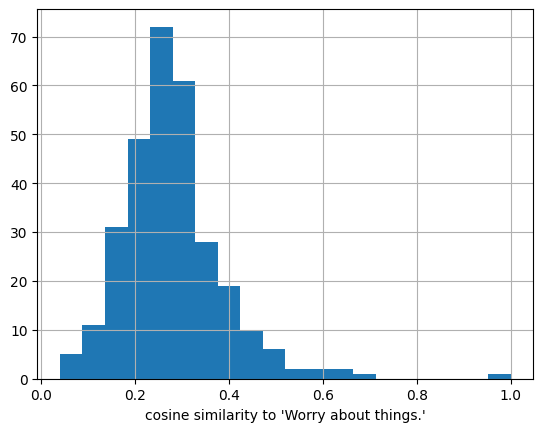

In [4]:
# Similarity matrix: 300 x 300, symmetric, 1 on the diagonal
predicted_sims = pd.DataFrame(cosine_similarity(item_features), index=personality['item'], columns=personality['item'])

# The items most similar to one anchor item, and the distribution of all its similarities
anchor = 'Worry about things.'
print(predicted_sims[anchor].sort_values(ascending=False).head(8).round(2).to_string())
predicted_sims[anchor].hist(bins=20)
plt.xlabel(f"cosine similarity to '{anchor}'");

**TASK 1**: Replace the anchor with other items (copy one from the table in section 1). Do the nearest neighbours make psychological sense? Is the distribution wide or narrow, and what would a very narrow one mean?

## 4. Comparing with what participants actually do

The model's similarities are a prediction. The observed similarity between two items is the correlation between participants' responses to them. The cell below loads the observed correlations, aligns the two matrices, flattens their upper triangles into vectors, and correlates the two.

Run the cell below.

In [5]:
# Load the observed correlations and pivot to a 300 x 300 matrix
observed_sims = pd.read_csv(DATA + 'item_corrs.csv').pivot(index='text_i', columns='text_j', values='cor')

# Same order of rows and columns in both matrices
predicted_sims, observed_sims = predicted_sims.align(observed_sims)

def upper_triangle(df):
    """Flatten the upper triangle of a square DataFrame (excluding the diagonal) into a Series"""
    rows, cols = np.triu_indices(len(df), k=1)
    return pd.Series(df.values[rows, cols])

predicted_flat, observed_flat = upper_triangle(predicted_sims), upper_triangle(observed_sims)

print(f"r(predicted, observed):     {predicted_flat.corr(observed_flat):.2f}")
print(f"r of absolute values:       {predicted_flat.abs().corr(observed_flat.abs()):.2f}")

r(predicted, observed):     0.18
r of absolute values:       0.33


The correlation is modest, and clearly higher on absolute values. The model is not told which way an item is keyed, so *Worry about things* and *Am relaxed most of the time* look alike to it although they correlate negatively. The cell below lists such pairs.

Run the cell below.

In [6]:
rows, cols = np.triu_indices(len(predicted_sims), k=1)
pairs = pd.DataFrame({
    'item_i': predicted_sims.index[rows], 'item_j': predicted_sims.columns[cols],
    'predicted': predicted_sims.values[rows, cols], 'observed': observed_sims.values[rows, cols],
})

# Similar according to the model, opposite according to participants
pairs.query('observed < -0.3').sort_values('predicted', ascending=False).head(10).round(2)

,item_i,item_j,predicted,observed
18402,Can handle complex problems.,Like to solve complex problems.,0.77,-0.55
29625,Feel comfortable around people.,Feel comfortable with myself.,0.75,-0.40
389,Act wild and crazy.,Do crazy things.,0.74,-0.75
2752,Am afraid to draw attention to myself.,Don't like to draw attention to myself.,0.73,-0.66
29724,Feel comfortable around people.,Only feel comfortable with friends.,0.72,-0.50
30971,Find it difficult to approach others.,Try to lead others.,0.64,-0.34
41849,Often feel uncomfortable around others.,Only feel comfortable with friends.,0.63,-0.48
26424,Don't like to draw attention to myself.,Make myself the center of attention.,0.63,-0.63
4489,Am comfortable in unfamiliar situations.,Feel comfortable around people.,0.62,-0.35
4586,Am comfortable in unfamiliar situations.,Often feel uncomfortable around others.,0.60,-0.31


**TASK 2**: Is a correlation of .33 something the model could produce by chance? The cell below shuffles which item is which in the observed matrix and recomputes the correlation 1,000 times. Run it, then explain in one sentence to your neighbour what the grey histogram and the red line are.

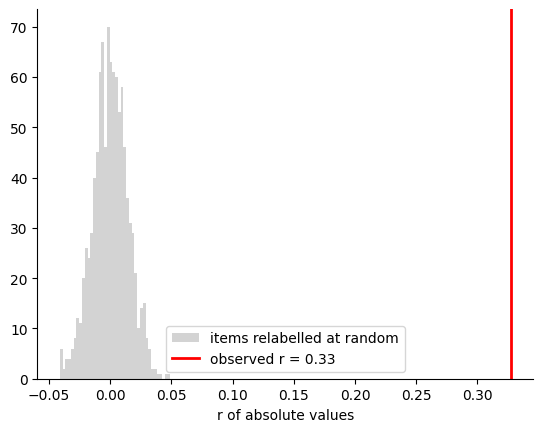

In [7]:
rng = np.random.default_rng(0)
observed_r = predicted_flat.abs().corr(observed_flat.abs())
null_r = []
for _ in range(1000):
    p = rng.permutation(len(observed_sims))                   # relabel the items at random
    shuffled = np.abs(observed_sims.values[np.ix_(p, p)][rows, cols])
    null_r.append(np.corrcoef(predicted_flat.abs(), shuffled)[0, 1])

plt.hist(null_r, bins=40, color='lightgrey', label='items relabelled at random')
plt.axvline(observed_r, color='red', linewidth=2, label=f'observed r = {observed_r:.2f}')
plt.xlabel('r of absolute values'); plt.legend(); sns.despine()

## 5. Mapping the items in two dimensions

PaCMAP reduces the 384 features to two while preserving neighbourhoods. The cell below fits it to the item features and plots every item, coloured by factor.

Run the cell below.

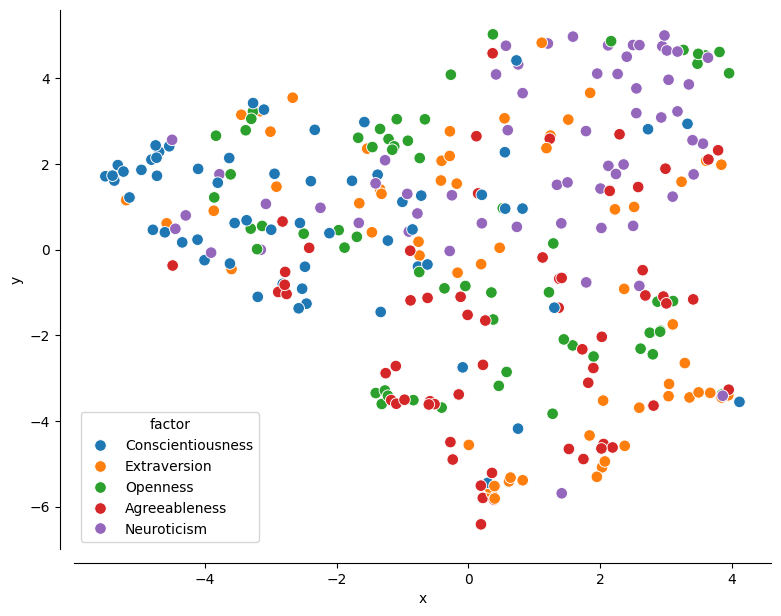

In [8]:
from pacmap import PaCMAP

xy = PaCMAP(n_components=2, random_state=42).fit_transform(item_features.values)
item_map = pd.DataFrame(xy, columns=['x', 'y'])
item_map['factor'] = personality['factor']
item_map['item'] = personality['item']

plt.figure(figsize=(9, 7))
sns.scatterplot(data=item_map, x='x', y='y', hue='factor', s=70)
sns.despine(offset=10)

Do not expect five clean clusters. A general-purpose model places items by what they are about, and the Big Five are not topics: *Love to eat* and *Dislike new foods* sit together whatever their factor. What you see are small local groups of items that share a theme.

The helper below lists the items around any point on the map. Read the coordinates of a spot off the axes, put them in, and widen or narrow the radius.

Run the cell below, then change the point.

In [9]:
def near(x, y, radius=0.6):
    """Items within `radius` of the point (x, y) on the map, nearest first."""
    dist = np.sqrt((item_map['x'] - x) ** 2 + (item_map['y'] - y) ** 2)
    return item_map.assign(distance=dist.round(2)).query('distance <= @radius').sort_values('distance')[['item', 'factor', 'distance']]

near(0.2, -5.5)

,item,factor,distance
222,Take advantage of others.,Agreeableness,0.01
129,Get others to do my duties.,Conscientiousness,0.11
79,Wait for others to lead the way.,Extraversion,0.13
161,Involve others in what I am doing.,Extraversion,0.20
72,Try to lead others.,Extraversion,0.25
49,Take no time for others.,Agreeableness,0.30
227,Use others for my own ends.,Agreeableness,0.33
154,Warm up quickly to others.,Extraversion,0.37
109,Get back at others.,Agreeableness,0.39
74,Seek to influence others.,Extraversion,0.43


**TASK 3**: Pick a tight single-colour group, read its centre off the axes and call `near(x, y)`. What do the items share: a factor, or a theme? Then pick a spot where two colours overlap, for example `near(2, -2, radius=1)`. Can *you* tell which factor each item belongs to?

## 6. Recovering the constructs from the item text

Can the model tell which facet an item measures without any response data? The cell below embeds the 30 facet names, computes the similarity between each facet name and each item, and assigns each item to the closest facet. It then prints the accuracy and draws the confusion matrix, ordered by factor.

Run the cell below.

Accuracy: 0.23   (chance = 0.03)


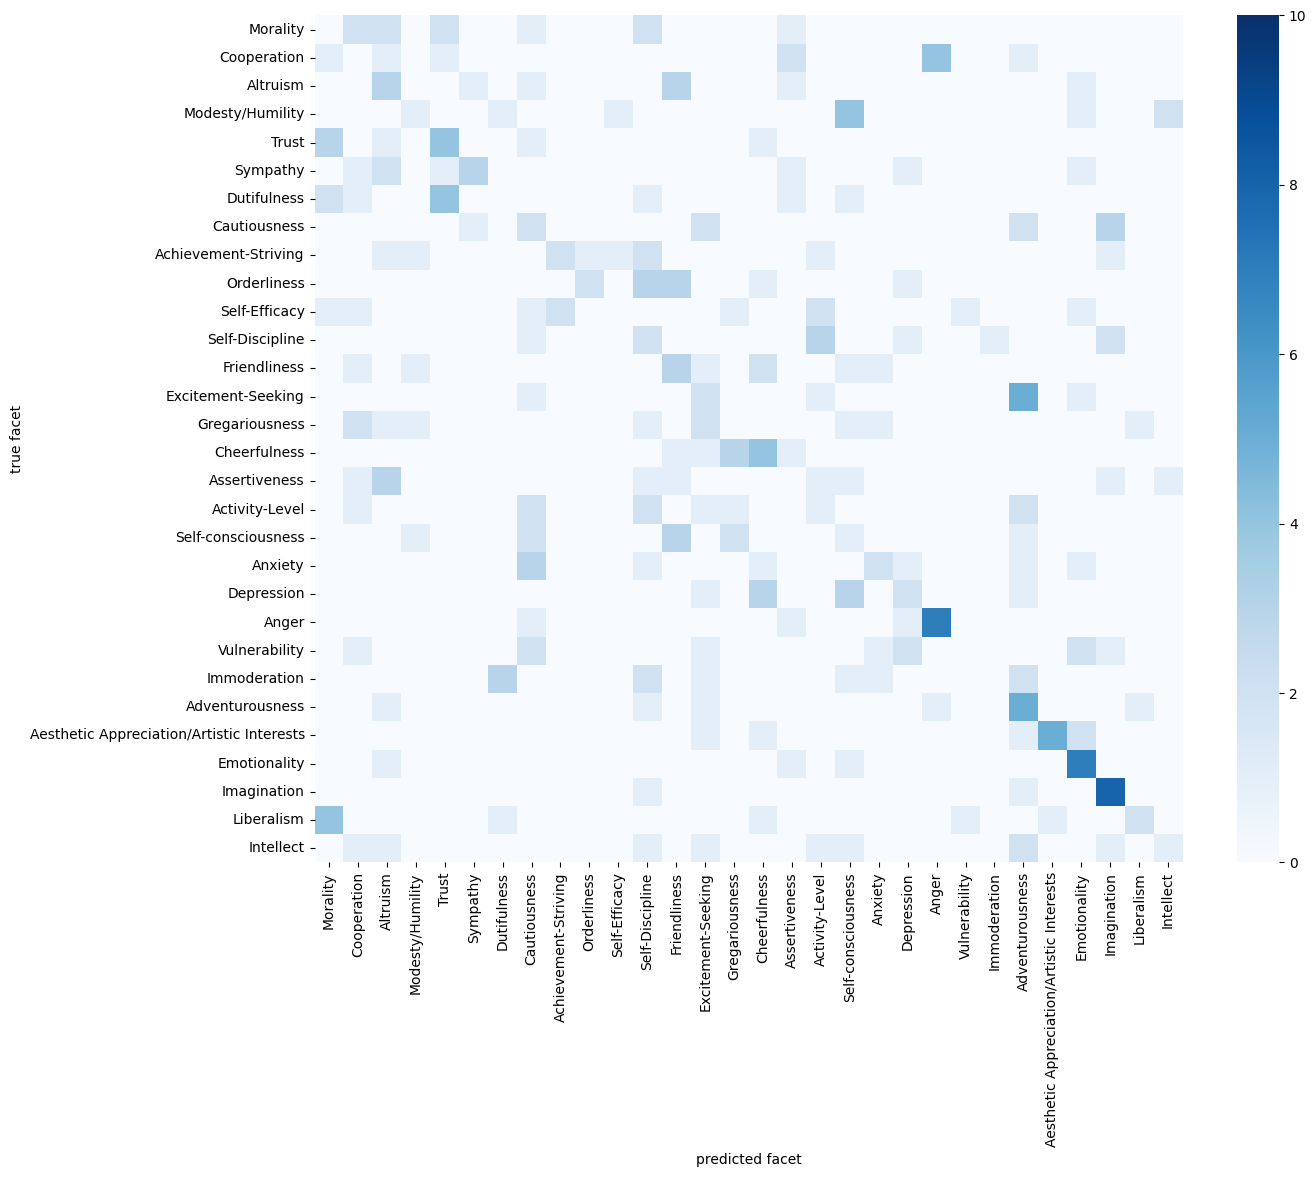

In [10]:
constructs = personality['construct'].unique().tolist()
construct_features = pd.DataFrame(model.encode(constructs), index=constructs)

# Similarity between every facet name and every item; closest facet per item
construct_item_sims = pd.DataFrame(cosine_similarity(construct_features, item_features), index=constructs, columns=item_features.index)
personality['predicted_construct'] = personality['item'].map(construct_item_sims.idxmax())

accuracy = (personality['construct'] == personality['predicted_construct']).mean()
print(f"Accuracy: {accuracy:.2f}   (chance = {1/len(constructs):.2f})")

# Confusion matrix: rows = true facet, columns = predicted facet, ordered by factor
order = personality.sort_values('factor')['construct'].unique()
confusion = pd.crosstab(personality['construct'], personality['predicted_construct']).reindex(index=order, columns=order, fill_value=0)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(confusion, cmap='Blues', vmin=0, vmax=10, ax=ax)
ax.set_xlabel('predicted facet'); ax.set_ylabel('true facet');

Some facets are recovered well, often *Emotionality* and *Imagination*. Most are not. Two readings are possible: the model does not understand the facet names well enough, or the facets are less distinct than the questionnaire implies. Both are interesting for a psychologist, and the confusion matrix tells you which facets get confused with which.

**TASK 4**: Find the two facets that get mixed up most often, read their items, and decide: is the confusion the model's fault, or the questionnaire's? Hint: `confusion` is a DataFrame, so `confusion.where(~np.eye(len(confusion), dtype=bool), 0).stack().sort_values(ascending=False).head()` lists the largest entries off the diagonal, and `personality[personality['construct'].isin([...])]` shows the items of the facets you name.

## 7. Your own item, and a new edition

The model has never seen the item you are about to write. The cell below returns its nearest existing items and the facet it lands in.

Run the cell below, then change `my_item`.

In [11]:
my_item = 'Love trying food I have never eaten before.'   # <- replace with an item of your own

my_vec = model.encode([my_item])
nearest_items = pd.Series(cosine_similarity(my_vec, item_features)[0], index=item_features.index).sort_values(ascending=False)
nearest_facets = pd.Series(cosine_similarity(my_vec, construct_features)[0], index=constructs).sort_values(ascending=False)

print('Closest existing items:'); print(nearest_items.head(5).round(2).to_string())
print('\nClosest facets:');        print(nearest_facets.head(3).round(2).to_string())

Closest existing items:
item
Love to eat.                       0.70
Dislike new foods.                 0.52
Am able to control my cravings.    0.49
Willing to try anything once.      0.43
Love to help others.               0.37

Closest facets:
Adventurousness       0.32
Gregariousness        0.25
Excitement-Seeking    0.22


**TASK 5**: Imagine a revised edition of the questionnaire. Take an existing item and reword it as an editor might (*Worry about things* to *Tend to be anxious about small matters*). Put the new wording into `my_item`. How similar is it to the original, and does it land in the same facet? This is the logic for asking where two editions of a test diverge.

**TASK 6**: Write a reverse-keyed item for a facet, such as *Rarely worry about anything*. Where does it land, and why?

## 8. A model that knows what items are

Everything so far used a general-purpose model. `dwulff/mpnet-personality` is the same kind of model fine-tuned on pairs of personality items to predict their observed correlation. The cell below loads it (about 420 MB, one minute on Colab) and repeats the three key results: the correlation from section 4, the map from section 5, and the accuracy from section 6.

Run the cell below.

r of absolute values:  general-purpose 0.33   fine-tuned 0.95
facet accuracy:        general-purpose 0.23   fine-tuned 0.45


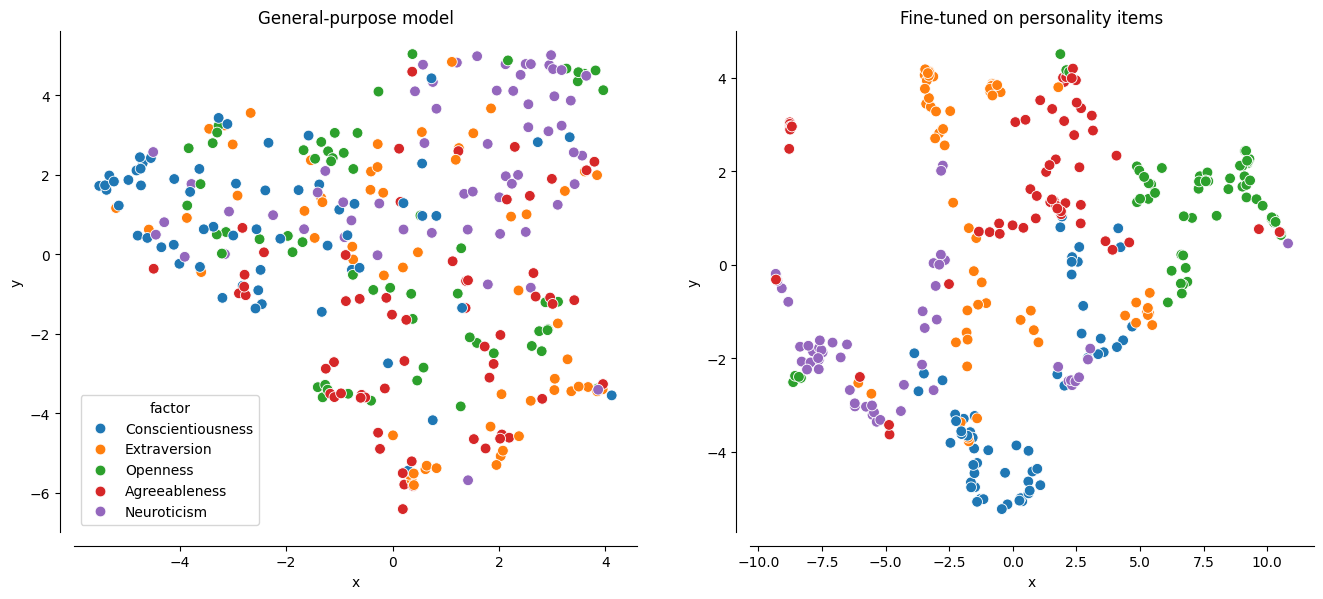

In [12]:
tuned_model = SentenceTransformer('dwulff/mpnet-personality')
tuned_features = pd.DataFrame(tuned_model.encode(personality['item'].tolist()), index=personality['item'])

# Correlation with observed
tuned_sims, _ = pd.DataFrame(cosine_similarity(tuned_features), index=personality['item'], columns=personality['item']).align(observed_sims)
tuned_flat = upper_triangle(tuned_sims)
print(f"r of absolute values:  general-purpose {observed_r:.2f}   fine-tuned {tuned_flat.abs().corr(observed_flat.abs()):.2f}")

# Facet accuracy
tuned_constructs = pd.DataFrame(tuned_model.encode(constructs), index=constructs)
tuned_closest = pd.DataFrame(cosine_similarity(tuned_constructs, tuned_features), index=constructs, columns=item_features.index).idxmax()
tuned_accuracy = (personality['construct'] == personality['item'].map(tuned_closest)).mean()
print(f"facet accuracy:        general-purpose {accuracy:.2f}   fine-tuned {tuned_accuracy:.2f}")

# The two maps side by side
tuned_map = pd.DataFrame(PaCMAP(n_components=2, random_state=42).fit_transform(tuned_features.values), columns=['x', 'y'])
tuned_map['factor'] = personality['factor']

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.scatterplot(data=item_map, x='x', y='y', hue='factor', s=60, ax=axes[0]).set_title('General-purpose model')
sns.scatterplot(data=tuned_map, x='x', y='y', hue='factor', s=60, ax=axes[1], legend=False).set_title('Fine-tuned on personality items')
sns.despine(offset=10)

Same items, same projection, same colours. The clusters that were missing appear once the model has learned what items measure, and the correlation with participants' answers jumps.

**TASK 7**: That model was fine-tuned on the very items we evaluate it on. Why is that an unfair advantage, and what would a fair test look like? What would you need to build such a model for your own test?

**BONUS TASK**: Change the model name in section 2 to `'dwulff/mpnet-personality'` and rerun the notebook from the top with *Runtime -> Run all*. Look at the keying pairs in section 4 and the confusion matrix in section 6 with the fine-tuned model.